In [3]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
sys.path.append(str(PROJECT_ROOT))

import numpy as np
import pandas as pd

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)


from src.data import load_and_clean_data, split_data

In [4]:
DATA_PATH = "../data/raw/Sarcasm_Headlines_Dataset.json"

df = load_and_clean_data(DATA_PATH)

X_train, X_val, X_test, y_train, y_val, y_test = split_data(df)

In [5]:
train_df = pd.DataFrame({
    "text": X_train.values,
    "label": y_train.values
})

val_df = pd.DataFrame({
    "text": X_val.values,
    "label": y_val.values
})

test_df = pd.DataFrame({
    "text": X_test.values,
    "label": y_test.values
})

train_dataset = Dataset.from_dict({
    "text": X_train.astype(str).tolist(),
    "label": y_train.astype(int).tolist()
})

val_dataset = Dataset.from_dict({
    "text": X_val.astype(str).tolist(),
    "label": y_val.astype(int).tolist()
})

test_dataset = Dataset.from_dict({
    "text": X_test.astype(str).tolist(),
    "label": y_test.astype(int).tolist()
})

In [6]:
MODEL_NAME = "distilbert/distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

/Users/sangeetha/opt/anaconda3/envs/sarcasm-nlp/lib/python3.10/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


In [7]:
def tokenize(batch):
    return tokenizer(
        batch["text"],
        truncation=True
    )

train_tokenized = train_dataset.map(
    tokenize,
    batched=True
)

val_tokenized = val_dataset.map(
    tokenize,
    batched=True
)

test_tokenized = test_dataset.map(
    tokenize,
    batched=True
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

Map:   0%|          | 0/19952 [00:00<?, ? examples/s]

Map:   0%|          | 0/4275 [00:00<?, ? examples/s]

Map:   0%|          | 0/4276 [00:00<?, ? examples/s]

In [8]:
id2label = {
    0: "NOT_SARCASTIC",
    1: "SARCASTIC"
}

label2id = {
    "NOT_SARCASTIC": 0,
    "SARCASTIC": 1
}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id
)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [9]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(
        logits,
        axis=-1
    )

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        zero_division=0
    )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [10]:
training_args = TrainingArguments(
    output_dir="../models/distilbert-sarcasm",

    learning_rate=2e-5,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    num_train_epochs=3,

    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    

    logging_steps=100,

    report_to="none"
)

In [12]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,

    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,

    tokenizer=tokenizer,
    data_collator=data_collator,

    compute_metrics=compute_metrics
)

print("Trainer initialized successfully!")

Trainer initialized successfully!


In [13]:
trainer.train()

  0%|          | 0/3741 [00:00<?, ?it/s]

{'loss': 0.5408, 'grad_norm': 8.083455085754395, 'learning_rate': 1.946538358727613e-05, 'epoch': 0.08}
{'loss': 0.3298, 'grad_norm': 14.343599319458008, 'learning_rate': 1.8930767174552262e-05, 'epoch': 0.16}
{'loss': 0.3314, 'grad_norm': 8.697463989257812, 'learning_rate': 1.8396150761828387e-05, 'epoch': 0.24}
{'loss': 0.2809, 'grad_norm': 11.602935791015625, 'learning_rate': 1.786153434910452e-05, 'epoch': 0.32}
{'loss': 0.3005, 'grad_norm': 8.143918991088867, 'learning_rate': 1.7326917936380647e-05, 'epoch': 0.4}
{'loss': 0.2778, 'grad_norm': 4.177992820739746, 'learning_rate': 1.679230152365678e-05, 'epoch': 0.48}
{'loss': 0.249, 'grad_norm': 8.078893661499023, 'learning_rate': 1.6257685110932907e-05, 'epoch': 0.56}
{'loss': 0.2625, 'grad_norm': 2.5910701751708984, 'learning_rate': 1.5723068698209036e-05, 'epoch': 0.64}
{'loss': 0.2448, 'grad_norm': 6.648965358734131, 'learning_rate': 1.5188452285485164e-05, 'epoch': 0.72}
{'loss': 0.2538, 'grad_norm': 13.570233345031738, 'learni

  0%|          | 0/268 [00:00<?, ?it/s]

{'eval_loss': 0.2176385372877121, 'eval_accuracy': 0.9141520467836257, 'eval_precision': 0.941207627118644, 'eval_recall': 0.8740777176586325, 'eval_f1': 0.90640142820709, 'eval_runtime': 17.5057, 'eval_samples_per_second': 244.206, 'eval_steps_per_second': 15.309, 'epoch': 1.0}
{'loss': 0.1596, 'grad_norm': 16.93532943725586, 'learning_rate': 1.3049986634589681e-05, 'epoch': 1.04}
{'loss': 0.1388, 'grad_norm': 2.679039716720581, 'learning_rate': 1.2515370221865812e-05, 'epoch': 1.12}
{'loss': 0.1556, 'grad_norm': 19.43743324279785, 'learning_rate': 1.198075380914194e-05, 'epoch': 1.2}
{'loss': 0.1534, 'grad_norm': 12.903170585632324, 'learning_rate': 1.1446137396418072e-05, 'epoch': 1.28}
{'loss': 0.1547, 'grad_norm': 15.222758293151855, 'learning_rate': 1.0911520983694199e-05, 'epoch': 1.36}
{'loss': 0.1523, 'grad_norm': 21.860414505004883, 'learning_rate': 1.037690457097033e-05, 'epoch': 1.44}
{'loss': 0.1305, 'grad_norm': 17.07434844970703, 'learning_rate': 9.842288158246459e-06, '

  0%|          | 0/268 [00:00<?, ?it/s]

{'eval_loss': 0.22662164270877838, 'eval_accuracy': 0.9335672514619883, 'eval_precision': 0.9251336898395722, 'eval_recall': 0.9360550909985244, 'eval_f1': 0.930562347188264, 'eval_runtime': 27.9713, 'eval_samples_per_second': 152.835, 'eval_steps_per_second': 9.581, 'epoch': 2.0}
{'loss': 0.1208, 'grad_norm': 0.8134860396385193, 'learning_rate': 6.634589681903235e-06, 'epoch': 2.0}
{'loss': 0.0656, 'grad_norm': 8.779420852661133, 'learning_rate': 6.099973269179365e-06, 'epoch': 2.09}
{'loss': 0.0776, 'grad_norm': 0.40949660539627075, 'learning_rate': 5.565356856455494e-06, 'epoch': 2.17}
{'loss': 0.0775, 'grad_norm': 0.4608016610145569, 'learning_rate': 5.030740443731623e-06, 'epoch': 2.25}
{'loss': 0.0864, 'grad_norm': 0.2085157185792923, 'learning_rate': 4.4961240310077525e-06, 'epoch': 2.33}
{'loss': 0.0725, 'grad_norm': 0.17219452559947968, 'learning_rate': 3.961507618283882e-06, 'epoch': 2.41}
{'loss': 0.0664, 'grad_norm': 7.357278347015381, 'learning_rate': 3.426891205560011e-06

  0%|          | 0/268 [00:00<?, ?it/s]

{'eval_loss': 0.2877235412597656, 'eval_accuracy': 0.9321637426900585, 'eval_precision': 0.9377197388247112, 'eval_recall': 0.9183472700442695, 'eval_f1': 0.9279324055666004, 'eval_runtime': 27.9218, 'eval_samples_per_second': 153.106, 'eval_steps_per_second': 9.598, 'epoch': 3.0}
{'train_runtime': 2084.5999, 'train_samples_per_second': 28.713, 'train_steps_per_second': 1.795, 'train_loss': 0.16964261626152075, 'epoch': 3.0}


TrainOutput(global_step=3741, training_loss=0.16964261626152075, metrics={'train_runtime': 2084.5999, 'train_samples_per_second': 28.713, 'train_steps_per_second': 1.795, 'total_flos': 363573334036224.0, 'train_loss': 0.16964261626152075, 'epoch': 3.0})

In [14]:
val_results = trainer.evaluate()

val_results

  0%|          | 0/268 [00:00<?, ?it/s]

{'eval_loss': 0.22662164270877838,
 'eval_accuracy': 0.9335672514619883,
 'eval_precision': 0.9251336898395722,
 'eval_recall': 0.9360550909985244,
 'eval_f1': 0.930562347188264,
 'eval_runtime': 27.032,
 'eval_samples_per_second': 158.146,
 'eval_steps_per_second': 9.914,
 'epoch': 3.0}

## DistilBERT Validation Results

The fine-tuned DistilBERT model achieved strong performance on the validation set:

- **Accuracy:** 93.36%
- **Precision:** 92.51%
- **Recall:** 93.61%
- **F1-score:** 93.06%
- **Validation Loss:** 0.2266

These results represent a substantial improvement over the classical TF-IDF models, which achieved approximately 85% validation accuracy.

The recall of 93.61% indicates that the model successfully identifies most sarcastic headlines, while the precision of 92.51% shows that the majority of headlines predicted as sarcastic are correctly classified.

The improvement suggests that contextual representations learned by DistilBERT are better suited to sarcasm detection than sparse lexical TF-IDF features. Unlike TF-IDF, the transformer model can represent words in relation to their surrounding context, which is particularly important for detecting semantic incongruity and subtle sarcastic language.

Overall, DistilBERT currently provides the strongest validation performance in the project.

In [15]:
predictions = trainer.predict(val_tokenized)

logits = predictions.predictions
y_true = predictions.label_ids
y_pred = np.argmax(logits, axis=-1)

  0%|          | 0/268 [00:00<?, ?it/s]

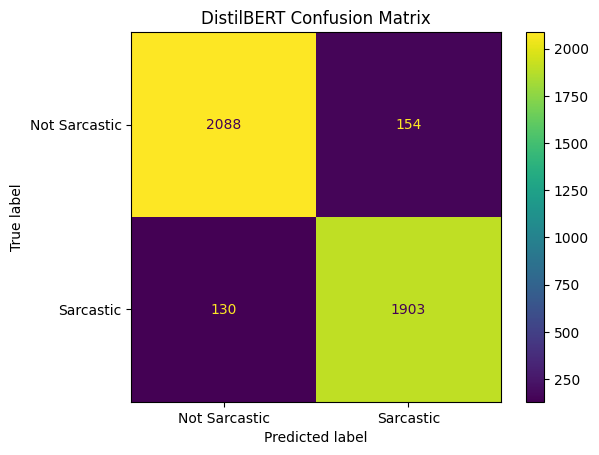

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=["Not Sarcastic", "Sarcastic"]
)

plt.title("DistilBERT Confusion Matrix")
plt.show()

In [17]:
from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(
    y_true,
    y_pred
).ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

True Negatives: 2088
False Positives: 154
False Negatives: 130
True Positives: 1903


## Error Analysis Dataframe

In [18]:
error_df = pd.DataFrame({
    "headline": X_val.values,
    "actual": y_true,
    "predicted": y_pred
})

error_df.head()

,headline,actual,predicted
0,sleepover guests get story straight on what ti...,1,1
1,no one speculating about family matters series...,1,1
2,did president trump really say he may have tap...,0,0
3,financial experts recommend young grifters sta...,1,1
4,shelter dog eating own shit not exactly doing ...,1,1


### Get all incorrect predictions

In [19]:
errors = error_df[
    error_df["actual"] != error_df["predicted"]
]

print("Total errors:", len(errors))

errors.head(20)

Total errors: 284


,headline,actual,predicted
13,nra spokesman: a hebrew?,1,0
31,americans take brief break from waiting on hol...,1,0
56,risk champ flunks geography test,1,0
70,that one chinese place closes,1,0
77,cops attempt to unlock phone of man they kille...,0,1
84,ugly custody battle over ian mckellen narrowly...,1,0
91,federal reserve accidentally leaks secret docu...,0,1
147,'fire rainbow' supplants double rainbow as soc...,0,1
156,obama to name former procter & gamble executiv...,0,1
162,little debbie conquers jenny craig in midnight...,1,0


In [22]:
#Inspect false positives 

false_positives = error_df[
    (error_df["actual"] == 0) &
    (error_df["predicted"] == 1)
]

false_positives.head(15)

,headline,actual,predicted
77,cops attempt to unlock phone of man they kille...,0,1
91,federal reserve accidentally leaks secret docu...,0,1
147,'fire rainbow' supplants double rainbow as soc...,0,1
156,obama to name former procter & gamble executiv...,0,1
166,stealth lobbying campaign blamed elizabeth war...,0,1
179,nurses ignore hospital regulations to grant dy...,0,1
181,chelsea clinton stops by aclu event to tell am...,0,1
187,kevin hart humors woman who thinks he's chris ...,0,1
197,prison inmates name feared guard known as 'cap...,0,1
240,airborne rally car misses hitting world's luck...,0,1


In [23]:
#false negatives

false_negatives = error_df[
    (error_df["actual"] == 1) &
    (error_df["predicted"] == 0)
]

false_negatives.head(15)

,headline,actual,predicted
13,nra spokesman: a hebrew?,1,0
31,americans take brief break from waiting on hol...,1,0
56,risk champ flunks geography test,1,0
70,that one chinese place closes,1,0
84,ugly custody battle over ian mckellen narrowly...,1,0
162,little debbie conquers jenny craig in midnight...,1,0
237,entertainment lawyer 'fighting the good fight',1,0
243,rick scott orders hurricane michael to evacuat...,1,0
296,gop attacks christine blasey ford for never co...,1,0
310,faa to ban plane crashes,1,0


In [24]:
#Convert logits to probabilities:
import torch

probabilities = torch.softmax(
    torch.tensor(logits),
    dim=1
).numpy()

confidence = probabilities.max(axis=1)

In [25]:
error_df["confidence"] = confidence

In [26]:
confident_errors = error_df[
    error_df["actual"] != error_df["predicted"]
].sort_values(
    "confidence",
    ascending=False
)

confident_errors.head(20)

,headline,actual,predicted,confidence
1822,what grieving widow needs is a day at the spa,1,0,0.998578
2756,"mosquitoes don't even need to bite us, study s...",1,0,0.998576
305,'take your kid to work day' results in npr new...,0,1,0.998474
3051,trouble again in tv's africa,1,0,0.998357
450,mel gibson - his performance in 'payback' stil...,1,0,0.998272
1515,alan colmes' death goes unreported on hannity ...,1,0,0.998153
3165,senate can't pass methane rollback so interior...,0,1,0.998056
197,prison inmates name feared guard known as 'cap...,0,1,0.998004
3101,whatsapp finally adds fully-encrypted video ca...,0,1,0.997914
2711,santa obliges dad of sleeping boy by snoozing ...,0,1,0.997900


## DistilBERT Error Analysis

The confusion matrix is used to examine how the transformer model performs across both classes and to identify the types of mistakes it still makes.

The analysis focuses on:

- **False Positives:** non-sarcastic headlines incorrectly predicted as sarcastic
- **False Negatives:** sarcastic headlines incorrectly predicted as non-sarcastic
- **High-confidence errors:** incorrect predictions where the model was strongly confident

Although DistilBERT substantially outperforms the classical TF-IDF models, some headlines remain difficult to classify.

These errors may arise from ambiguous wording, subtle sarcasm, world knowledge requirements, or publication-specific writing styles. Examining these mistakes helps reveal limitations that are not visible from aggregate accuracy and F1-score alone.

## Error Analysis Findings

The DistilBERT model produced the following confusion matrix results on the validation set:

- **True Negatives:** 2,088
- **False Positives:** 154
- **False Negatives:** 130
- **True Positives:** 1,903
- **Total Errors:** 284

This represents a substantial reduction in classification errors compared with the classical TF-IDF models.

### False Positives

False positives are non-sarcastic headlines that the model incorrectly classified as sarcastic.

Several of these headlines contain unusual, surprising, sensational, or ironic-sounding language. For example, headlines involving accidental events, unusual political stories, or humorous real-world situations may resemble the style of satirical news even though they are genuine headlines.

This suggests that the model can sometimes confuse **unusual real-world events with satire**.

### False Negatives

False negatives are sarcastic headlines that the model incorrectly classified as non-sarcastic.

Some of these headlines resemble conventional news writing and contain few obvious lexical indicators of sarcasm. Their sarcastic meaning may depend on background knowledge, implied absurdity, or cultural context.

This suggests that even a contextual transformer model may struggle when sarcasm is subtle or when understanding the joke requires knowledge beyond the text itself.

### Overall Interpretation

DistilBERT substantially improves sarcasm detection compared with TF-IDF-based Logistic Regression and Linear SVM.

The remaining errors show that sarcasm detection is not purely a lexical classification problem. Some examples require:

- background or world knowledge,
- understanding of implied meaning,
- recognition of absurdity,
- knowledge of social or political context,
- or additional context beyond the headline itself.

These limitations are important when interpreting the model's strong overall performance.

In [ ]:
#Evaluate the model on the test set
test_results = trainer.evaluate(test_tokenized)

test_results

  0%|          | 0/268 [00:00<?, ?it/s]

{'eval_loss': 0.2689701020717621,
 'eval_accuracy': 0.9251637043966323,
 'eval_precision': 0.9096126255380201,
 'eval_recall': 0.9355632070831283,
 'eval_f1': 0.9224054316197866,
 'eval_runtime': 28.9935,
 'eval_samples_per_second': 147.481,
 'eval_steps_per_second': 9.243,
 'epoch': 3.0}

In [28]:
#Get prediction

test_predictions = trainer.predict(test_tokenized)

test_logits = test_predictions.predictions
y_test_true = test_predictions.label_ids
y_test_pred = np.argmax(test_logits, axis=-1)

  0%|          | 0/268 [00:00<?, ?it/s]

In [30]:
# Classification report for the test set
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test_true,
        y_test_pred,
        target_names=["Not Sarcastic", "Sarcastic"]
    )
)

               precision    recall  f1-score   support

Not Sarcastic       0.94      0.92      0.93      2243
    Sarcastic       0.91      0.94      0.92      2033

     accuracy                           0.93      4276
    macro avg       0.92      0.93      0.93      4276
 weighted avg       0.93      0.93      0.93      4276



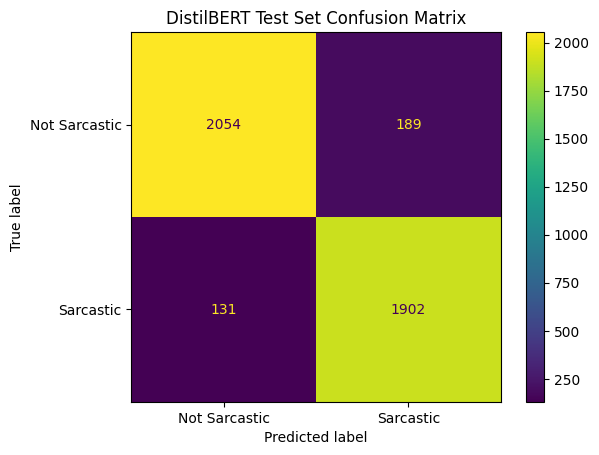

In [31]:
#Confusion matrix for test set
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test_true,
    y_test_pred,
    display_labels=["Not Sarcastic", "Sarcastic"]
)

plt.title("DistilBERT Test Set Confusion Matrix")
plt.show()

In [32]:
# Extract raw values
from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(
    y_test_true,
    y_test_pred
).ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

True Negatives: 2054
False Positives: 189
False Negatives: 131
True Positives: 1902


In [35]:
# Sae the final metrics 
final_test_metrics = pd.DataFrame([{
    "Model": "DistilBERT",
    "Accuracy": test_results["eval_accuracy"],
    "Precision": test_results["eval_precision"],
    "Recall": test_results["eval_recall"],
    "F1 Score": test_results["eval_f1"],
    "Test Loss": test_results["eval_loss"]
}])

final_test_metrics

,Model,Accuracy,Precision,Recall,F1 Score,Test Loss
0,DistilBERT,0.925164,0.909613,0.935563,0.922405,0.26897


In [34]:
final_test_metrics.to_csv(
    "../results/distilbert_test_metrics.csv",
    index=False
)

## Final Test Set Evaluation

After comparing all models on the validation set, DistilBERT was selected as the final model.

The untouched test set is now used for a single final evaluation to estimate how well the selected model generalizes to unseen data.

The test set was not used during model training, hyperparameter selection, or model comparison.

The final evaluation reports:

- Accuracy
- Precision
- Recall
- F1-score
- Test loss
- Confusion matrix

These results represent the final reported performance of the sarcasm detection system.

## Final Test Set Results

After selecting DistilBERT as the best-performing model on the validation set, the model was evaluated once on the previously untouched test set.

The final test performance was:

- **Accuracy:** 92.52%
- **Precision:** 90.96%
- **Recall:** 93.56%
- **F1-score:** 92.24%
- **Test Loss:** 0.2690

### Confusion Matrix

The model produced:

- **True Negatives:** 2,054
- **False Positives:** 189
- **False Negatives:** 131
- **True Positives:** 1,902

The model correctly identified the majority of both sarcastic and non-sarcastic headlines.

Recall for the sarcastic class remained particularly strong at approximately 93.56%, indicating that the model successfully detected most sarcastic examples in unseen data.

Precision was slightly lower at approximately 90.96%, which means that some non-sarcastic headlines were incorrectly classified as sarcastic.

### Generalization

The test performance is close to the validation performance, suggesting that the model generalizes well to unseen examples.

Validation F1-score was approximately **93.06%**, while the final test F1-score was approximately **92.24%**.

The relatively small difference between validation and test performance suggests that there is no strong evidence of severe overfitting.

### Final Conclusion

DistilBERT substantially outperformed the classical TF-IDF-based models and achieved an F1-score above 92% on the held-out test set.

These results support the conclusion that contextual transformer representations are more effective for sarcasm detection than sparse lexical representations such as TF-IDF on this dataset.

However, the remaining errors also demonstrate that sarcasm detection remains challenging when headlines depend on ambiguity, world knowledge, subtle humor, or context beyond the text itself.

In [36]:
MODEL_SAVE_PATH = "../models/distilbert-sarcasm-final"

trainer.save_model(MODEL_SAVE_PATH)
tokenizer.save_pretrained(MODEL_SAVE_PATH)

('../models/distilbert-sarcasm-final/tokenizer_config.json',
 '../models/distilbert-sarcasm-final/special_tokens_map.json',
 '../models/distilbert-sarcasm-final/vocab.txt',
 '../models/distilbert-sarcasm-final/added_tokens.json',
 '../models/distilbert-sarcasm-final/tokenizer.json')